**Deploying the Diabetes Logistic Model as a FastAPI Service**

Instructor Name: Attique-ur-Rehman

Student Name: Fatima Kashif

Sap Id: 70177832

In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn joblib

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

In [4]:
from google.colab import files
uploaded = files.upload()          # select diabetes.csv in the dialog

df = pd.read_csv("diabetes.csv")
print(df.shape)
df.head()

Saving diabetes.csv to diabetes.csv
(768, 8)


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    float64
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    float64
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 48.1 KB
None

Missing values:
 Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zeros per column:


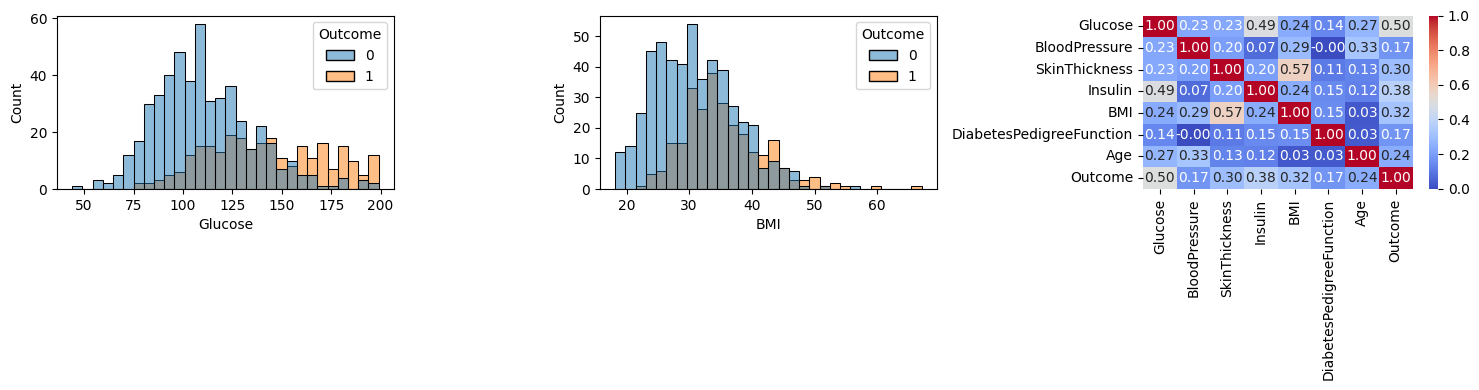

In [5]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nZeros per column:\n", (df.drop(columns="Outcome") == 0).sum())
print("\nClass balance:\n", df["Outcome"].value_counts(normalize=True).round(3))

baseline = 1 - df["Outcome"].mean()
print(f"\nBASELINE accuracy (always predict 'no diabetes'): {baseline:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=df, x="Glucose", hue="Outcome", bins=30, ax=ax[0])
sns.histplot(data=df, x="BMI", hue="Outcome", bins=30, ax=ax[1])
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[2])
plt.tight_layout(); plt.show()

In [6]:
print(pd.crosstab(df["Insulin"].where(df["Insulin"].isin([102.5, 169.5]), "other"), df["Outcome"]))

Outcome    0    1
Insulin          
102.5    236    0
169.5      0  138
other    264  130


In [7]:
FEATURES = [c for c in df.columns if c != "Outcome"]
X, y = df[FEATURES], df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)
print("Train rate:", round(y_train.mean(), 3), "| Test rate:", round(y_test.mean(), 3))

(614, 7) (154, 7)
Train rate: 0.349 | Test rate: 0.351


In [8]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=FEATURES, index=X_test.index)
joblib.dump(scaler, "diabetes_scaler.joblib")

['diabetes_scaler.joblib']

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(random_state=SEED),
    "Random Forest":       RandomForestClassifier(random_state=SEED),
}

def compare(models, Xtr, Xte, ytr, yte):
    rows, fitted = [], {}
    for name, m in models.items():
        m.fit(Xtr, ytr)
        rows.append({"Model": name,
                     "Accuracy": accuracy_score(yte, m.predict(Xte)),
                     "AUC": roc_auc_score(yte, m.predict_proba(Xte)[:, 1])})
        fitted[name] = m
    return pd.DataFrame(rows).set_index("Model").round(4), fitted

results, fitted = compare(models, X_train_s, X_test_s, y_train, y_test)
print(f"Baseline: {baseline:.3f}")
results

Baseline: 0.651


,Accuracy,AUC
Model,,
Logistic Regression,0.7273,0.8174
Decision Tree,0.8377,0.8111
Random Forest,0.8571,0.9436


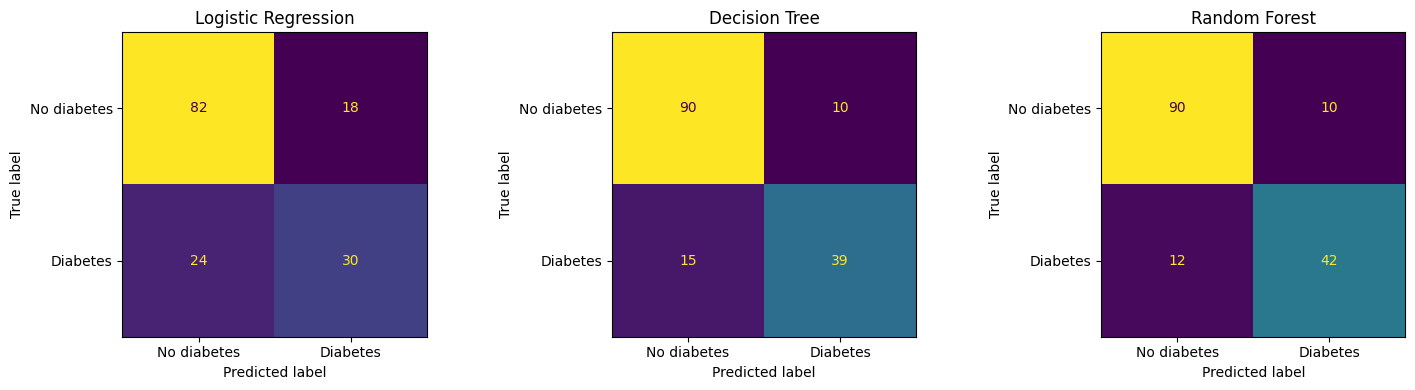


=== Logistic Regression ===
              precision    recall  f1-score   support

 No diabetes       0.77      0.82      0.80       100
    Diabetes       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154


=== Decision Tree ===
              precision    recall  f1-score   support

 No diabetes       0.86      0.90      0.88       100
    Diabetes       0.80      0.72      0.76        54

    accuracy                           0.84       154
   macro avg       0.83      0.81      0.82       154
weighted avg       0.84      0.84      0.84       154


=== Random Forest ===
              precision    recall  f1-score   support

 No diabetes       0.88      0.90      0.89       100
    Diabetes       0.81      0.78      0.79        54

    accuracy                           0.86       154
   macro avg       0.85      0.84      0.84       154

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test_s)),
                           display_labels=["No diabetes", "Diabetes"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name, m in fitted.items():
    print(f"\n=== {name} ===")
    print(classification_report(y_test, m.predict(X_test_s), target_names=["No diabetes", "Diabetes"]))

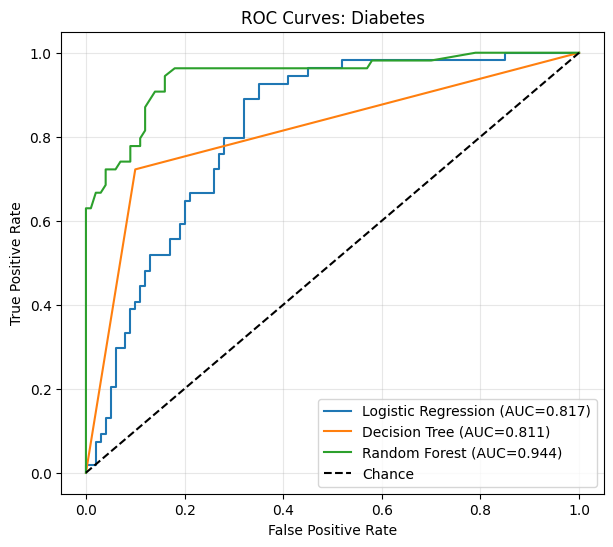

In [11]:
plt.figure(figsize=(7, 6))
for name, m in fitted.items():
    proba = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Diabetes"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("figures/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", m)])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"Model": name, "CV Mean": s.mean(), "CV Std": s.std()})
cv_table = pd.DataFrame(rows).set_index("Model").round(4)
cv_table

,CV Mean,CV Std
Model,,
Logistic Regression,0.7915,0.0205
Decision Tree,0.8240,0.0421
Random Forest,0.8729,0.0207


In [13]:
models_ext = {**models,
              "KNN": KNeighborsClassifier(),
              "SVC": SVC(probability=True, random_state=SEED)}
results_ext, _ = compare(models_ext, X_train_s, X_test_s, y_train, y_test)
results_ext.sort_values("Accuracy", ascending=False)

,Accuracy,AUC
Model,,
Random Forest,0.8571,0.9436
KNN,0.8377,0.8735
Decision Tree,0.8377,0.8111
SVC,0.8312,0.9061
Logistic Regression,0.7273,0.8174


In [14]:
param_grid = {
    "C":            [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty":      ["l1", "l2"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(
    LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED),
    param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_s, y_train)

best_model = grid.best_estimator_
print("Best params:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")
print(f"Test accuracy:    {accuracy_score(y_test, best_model.predict(X_test_s)):.4f}")
print(f"Test AUC:         {roc_auc_score(y_test, best_model.predict_proba(X_test_s)[:,1]):.4f}")

Best params: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l2'}
Best CV accuracy: 0.8078
Test accuracy:    0.7468
Test AUC:         0.8219


In [15]:
joblib.dump(best_model, "diabetes_best_model.joblib")
print([f for f in os.listdir(".") if f.startswith("diabetes") and f.endswith(".joblib")])

['diabetes_best_model.joblib', 'diabetes_scaler.joblib']


In [16]:
def predict_diabetes(glucose, blood_pressure, skin_thickness, insulin, bmi, pedigree, age):
    model = joblib.load("diabetes_best_model.joblib")
    scl   = joblib.load("diabetes_scaler.joblib")
    row = pd.DataFrame([{
        "Glucose": glucose, "BloodPressure": blood_pressure,
        "SkinThickness": skin_thickness, "Insulin": insulin, "BMI": bmi,
        "DiabetesPedigreeFunction": pedigree, "Age": age}])[FEATURES]
    p = model.predict_proba(scl.transform(row))[0, 1]
    return {"prediction": "DIABETIC" if p >= 0.5 else "NOT DIABETIC",
            "probability": round(float(p), 3)}

print(predict_diabetes(150, 70, 30, 150, 33, 0.6, 45))
print(predict_diabetes(90, 66, 23, 94, 24, 0.2, 25))

{'prediction': 'DIABETIC', 'probability': 0.756}
{'prediction': 'NOT DIABETIC', 'probability': 0.055}


In [17]:
pipe = Pipeline([("sc", StandardScaler()),
                 ("clf", LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED))])
pipe_grid = GridSearchCV(pipe,
    {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
     "clf__penalty": ["l1", "l2"],
     "clf__class_weight": [None, "balanced"]},
    cv=cv, scoring="accuracy", n_jobs=-1)
pipe_grid.fit(X_train, y_train)          # raw, unscaled X_train

print(f"Pipeline CV accuracy: {pipe_grid.best_score_:.4f}")
print(f"Manual   CV accuracy: {grid.best_score_:.4f}")
print(f"Pipeline test accuracy: {pipe_grid.score(X_test, y_test):.4f}")
joblib.dump(pipe_grid.best_estimator_, "diabetes_pipeline.joblib")

Pipeline CV accuracy: 0.8078
Manual   CV accuracy: 0.8078
Pipeline test accuracy: 0.7468


['diabetes_pipeline.joblib']